In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [22]:
import os

print(os.listdir())

['.config', 'student-mat.csv.zip', '.ipynb_checkpoints', 'sample_data']


In [24]:
import pandas as pd
import os

# Find the extracted CSV file
csv_path = None

for root, dirs, files in os.walk("student_data"):
    for file in files:
        if file == "student-mat.csv":
            csv_path = os.path.join(root, file)

# Load the dataset
if csv_path:
    df = pd.read_csv(csv_path, sep=";")
    print("Dataset loaded successfully!")
else:
    print("CSV file not found. Please check ZIP extraction.")

CSV file not found. Please check ZIP extraction.


In [25]:
import zipfile
import os

zip_path = "student-mat.csv.zip"

# Extract the ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files inside ZIP:", zip_ref.namelist())
    zip_ref.extractall("student_data")

print("\nZIP file extracted successfully!")

Files inside ZIP: ['.student.zip_old', 'student.zip']

ZIP file extracted successfully!


In [26]:
import zipfile

with zipfile.ZipFile("student_data/student.zip", "r") as zip_ref:
    print("Files inside second ZIP:", zip_ref.namelist())
    zip_ref.extractall("student_data/final")

print("Second ZIP extracted successfully!")

Files inside second ZIP: ['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']
Second ZIP extracted successfully!


In [27]:
import os

for root, dirs, files in os.walk("student_data/final"):
    for file in files:
        print(os.path.join(root, file))

student_data/final/student-por.csv
student_data/final/student-mat.csv
student_data/final/student.txt
student_data/final/student-merge.R


In [28]:
import pandas as pd
import os

csv_path = None

for root, dirs, files in os.walk("student_data/final"):
    for file in files:
        if file == "student-mat.csv":
            csv_path = os.path.join(root, file)

if csv_path:
    df = pd.read_csv(csv_path, sep=";")

    print("Dataset loaded successfully!")
    print(df.head())
    print("Dataset shape:", df.shape)

else:
    print("CSV file not found!")

Dataset loaded successfully!
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
Dataset shape: (395, 33)


In [29]:
print("All Dataset Columns:")

print(df.columns.tolist())

All Dataset Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [30]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [32]:
print(df.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

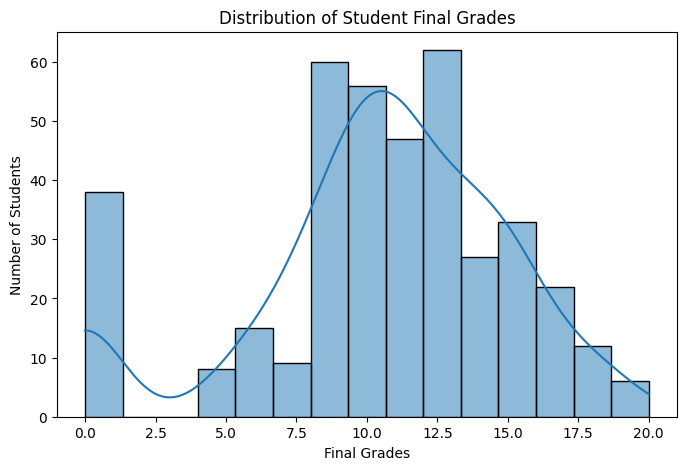

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Student Final Grades")

plt.xlabel("Final Grades")

plt.ylabel("Number of Students")

plt.show()

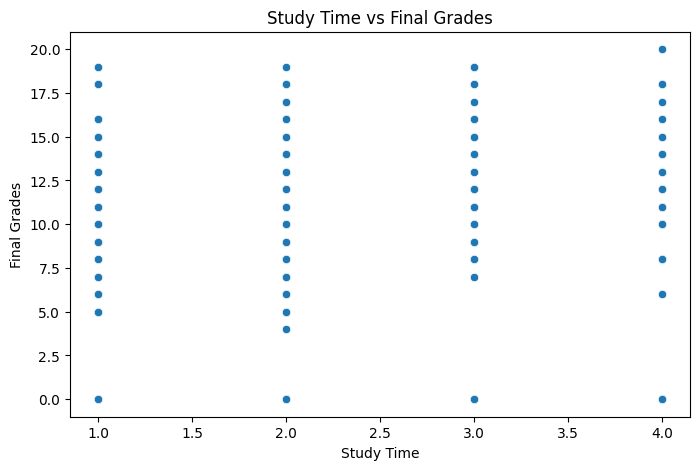

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Final Grades")

plt.xlabel("Study Time")

plt.ylabel("Final Grades")

plt.show()

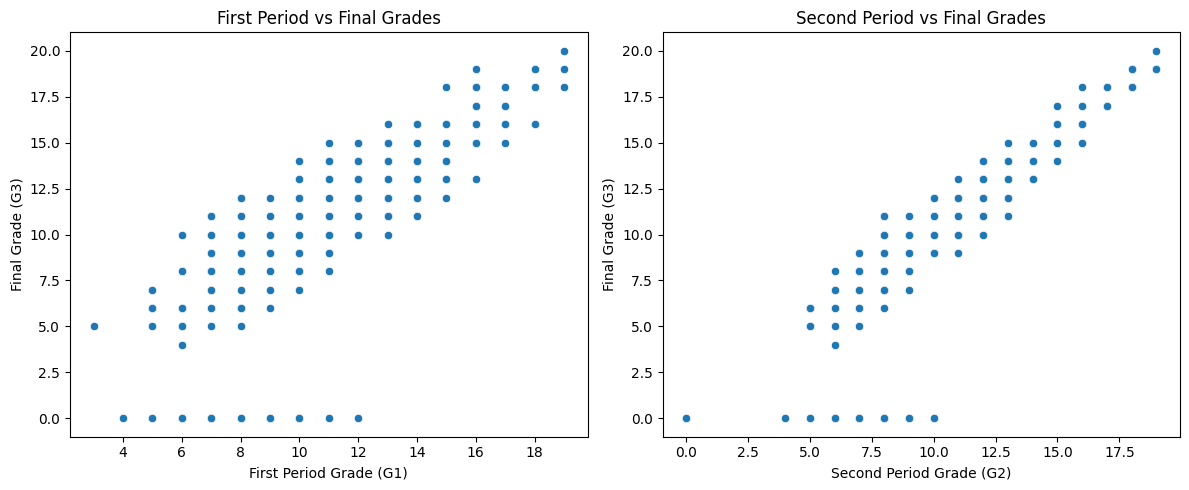

In [35]:
plt.figure(figsize=(12, 5))

# First graph: G1 vs G3
plt.subplot(1, 2, 1)

sns.scatterplot(data=df, x="G1", y="G3")

plt.title("First Period vs Final Grades")
plt.xlabel("First Period Grade (G1)")
plt.ylabel("Final Grade (G3)")


# Second graph: G2 vs G3
plt.subplot(1, 2, 2)

sns.scatterplot(data=df, x="G2", y="G3")

plt.title("Second Period vs Final Grades")
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.show()

In [36]:
features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "Medu",
    "Fedu",
    "G1",
    "G2"
]

X = df[features]

print("Selected Features:")
print(X.head())

Selected Features:
   age  studytime  failures  absences  Medu  Fedu  G1  G2
0   18          2         0         6     4     4   5   6
1   17          2         0         4     1     1   5   5
2   15          2         3        10     1     1   7   8
3   15          3         0         2     4     2  15  14
4   16          2         0         4     3     3   6  10


In [37]:
y = df["G3"]

print("Target Variable:")
print(y.head())

Target Variable:
0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64


In [38]:
print("Input data shape:", X.shape)

print("Target data shape:", y.shape)

print("Number of features:", len(features))

Input data shape: (395, 8)
Target data shape: (395,)
Number of features: 8


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)

print("Testing target:", y_test.shape)

Training data: (316, 8)
Testing data: (79, 8)
Training target: (316,)
Testing target: (79,)


In [40]:
from sklearn.linear_model import LinearRegression

# Create the model
model1 = LinearRegression()

# Train the model
model1.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [41]:
# Predict student final grades

predictions1 = model1.predict(X_test)

print("Predicted Student Grades:")

print(predictions1[:10])

Predicted Student Grades:
[ 6.26926394 11.94278087  3.05627361  8.84922663  7.35508224 12.44774917
 18.89490875  7.43747262  7.16956774 12.72618943]


In [42]:
comparison = pd.DataFrame({
    "Actual Grades": y_test.values[:10],
    "Predicted Grades": predictions1[:10]
})

print(comparison)

   Actual Grades  Predicted Grades
0             10          6.269264
1             12         11.942781
2              5          3.056274
3             10          8.849227
4              9          7.355082
5             13         12.447749
6             18         18.894909
7              6          7.437473
8              0          7.169568
9             14         12.726189


In [43]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model

model2 = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model

model2.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [44]:
predictions2 = model2.predict(X_test)

print("Random Forest Predictions:")

print(predictions2[:10])

Random Forest Predictions:
[ 8.33 11.89  6.79  9.74  8.94 13.39 18.73  6.79  5.58 13.12]


In [45]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

def evaluate_model(actual, predicted, name):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 2))


evaluate_model(y_test, predictions1, "Linear Regression")

evaluate_model(y_test, predictions2, "Random Forest")


Model: Linear Regression
MAE: 1.34
RMSE: 2.13
R2 Score: 0.78

Model: Random Forest
MAE: 1.08
RMSE: 1.76
R2 Score: 0.85


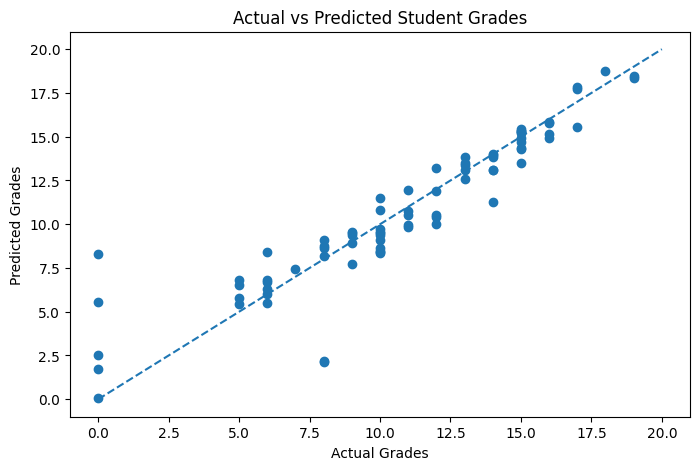

In [46]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions2)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.xlabel("Actual Grades")

plt.ylabel("Predicted Grades")

plt.title("Actual vs Predicted Student Grades")

plt.show()

In [47]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model2.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

     Feature  Importance
7         G2    0.797838
3   absences    0.114567
0        age    0.030598
5       Fedu    0.019228
6         G1    0.014424
1  studytime    0.009031
4       Medu    0.008971
2   failures    0.005342


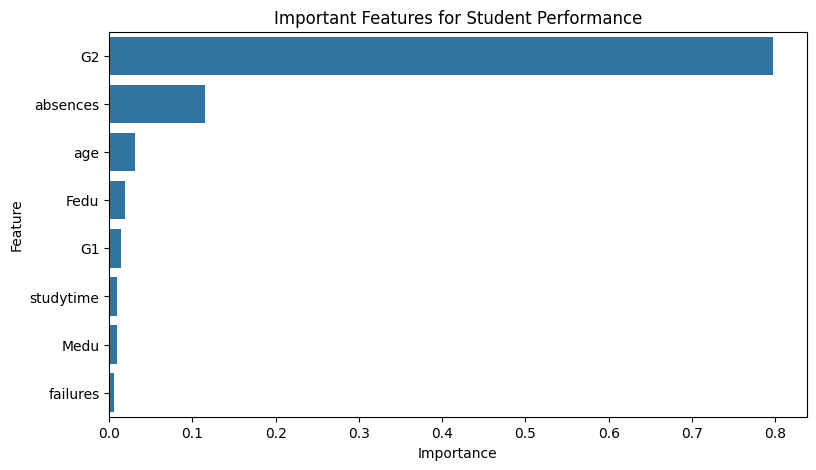

In [48]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Important Features for Student Performance")

plt.show()

In [49]:
import pandas as pd

new_student = pd.DataFrame([{
    "age": 18,
    "studytime": 3,
    "failures": 0,
    "absences": 2,
    "Medu": 4,
    "Fedu": 3,
    "G1": 15,
    "G2": 16
}])

print("New Student Information:")
print(new_student)

New Student Information:
   age  studytime  failures  absences  Medu  Fedu  G1  G2
0   18          3         0         2     4     3  15  16


In [50]:
prediction = model2.predict(new_student)

print("Predicted Final Grade:")

print(round(prediction[0], 2))

Predicted Final Grade:
16.77


In [51]:
predicted_grade = prediction[0]

print("================================")
print(" STUDENT PERFORMANCE PREDICTION")
print("================================")

print("Student Age: 18")

print("Study Time: 5-10 hours per week")

print("Previous Grade G1: 15")

print("Previous Grade G2: 16")

print("--------------------------------")

print("Predicted Final Grade:",
      round(predicted_grade, 2), "/ 20")

print("================================")

 STUDENT PERFORMANCE PREDICTION
Student Age: 18
Study Time: 5-10 hours per week
Previous Grade G1: 15
Previous Grade G2: 16
--------------------------------
Predicted Final Grade: 16.77 / 20


In [52]:
print("PROJECT: STUDENT PERFORMANCE PREDICTION")

print("\nDataset: UCI Student Performance")

print("Total Students:", len(df))

print("Total Features:", len(features))

print("\nAlgorithms Used:")

print("1. Linear Regression")

print("2. Random Forest")

print("\nBest Model: Random Forest")

print("Random Forest R2 Score: 0.85")

print("\nProject Completed Successfully!")

PROJECT: STUDENT PERFORMANCE PREDICTION

Dataset: UCI Student Performance
Total Students: 395
Total Features: 8

Algorithms Used:
1. Linear Regression
2. Random Forest

Best Model: Random Forest
Random Forest R2 Score: 0.85

Project Completed Successfully!
